# Task
Malware binary classification using the original gated MalConv architecture from [MalTorch](https://github.com/zangobot/maltorch).

Train from scratch on raw executable bytes. No malware is executed and no pretrained weights are downloaded.

---


# Prerequisites
Use Python 3.9+ and a dedicated environment. From this notebook's directory:

```sh
pip-compile requirements.in
pip install -r requirements.txt
```

Select that environment as the notebook kernel. The complete run can be slow on CPU. Files are loaded lazily from the ZIP, rather than keeping all executable bytes or padded inputs in memory. Start with a smaller batch size if GPU memory is limited.


In [1]:
from datetime import datetime
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path, PurePosixPath
import csv
import io
import random
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn import metrics
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from maltorch.zoo.malconv import MalConv
from tqdm.auto import tqdm

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/backend').is_dir())
NOTEBOOK_DIR = ROOT / 'Training/Malware_Detection_xai'
local_zip = NOTEBOOK_DIR / '.data/MalwareDetectionDataset.zip'
DATA_PATH = local_zip if local_zip.exists() else ROOT / 'src/backend/.data/malware_detection/MalwareDetectionDataset.zip'
seed = 123
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
print(f'MalTorch: {version("maltorch")} | PyTorch: {torch.__version__}')
print(f'Dataset: {DATA_PATH}')


MalTorch: 0.3.6 | PyTorch: 2.8.0
Dataset: /Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/src/backend/.data/malware_detection/MalwareDetectionDataset.zip


---
# Dataset
[DikeDataset](https://github.com/iosifache/DikeDataset): benign = 0, malware = 1. Use the service ZIP with `files/benign`, `files/malware`, `labels/benign`, and `labels/malware` at its root. Label CSVs require `hash`; other label columns are ignored. Class comes from folder membership.

### **Load** the manifest and validate file hashes.
Read samples as data inside the ZIP; do not extract or execute them. Record sizes and PE signatures for the next cells.


In [2]:
def is_pe_header(prefix, stream, size):
    if len(prefix) < 64 or prefix[:2] != b'MZ':
        return False
    offset = int.from_bytes(prefix[60:64], 'little')
    if offset < 64 or offset + 24 > size:
        return False
    stream.seek(offset)
    return stream.read(4) == b'PE\x00\x00'


# Fingerprint the archive in bounded chunks (works on Python 3.9 too).
archive_hash = sha256()
with DATA_PATH.open('rb') as stream:
    for chunk in iter(lambda: stream.read(1024 * 1024), b''):
        archive_hash.update(chunk)
dataset_version = f'sha256:{archive_hash.hexdigest()}'

rows, label_rows, directories, seen_paths = [], [], set(), set()
required_directories = {'files/benign', 'files/malware', 'labels/benign', 'labels/malware'}
with zipfile.ZipFile(DATA_PATH) as archive:
    for member in tqdm(archive.infolist(), desc='Validate dataset'):
        path = member.filename.rstrip('/')
        parts = path.split('/')
        if path in seen_paths or any(p in ('', '.', '..') for p in parts) or '\\' in path:
            raise ValueError(f'Duplicate or unsafe archive path: {path}')
        seen_paths.add(path)
        if member.is_dir():
            if path not in required_directories | {'files', 'labels'}:
                raise ValueError(f'Unexpected directory: {path}')
            if path in required_directories:
                directories.add(path)
            continue
        if len(parts) != 3 or '/'.join(parts[:2]) not in required_directories:
            raise ValueError(f'Unexpected archive member: {path}')
        directories.add('/'.join(parts[:2]))
        label = int(parts[1] == 'malware')
        if parts[0] == 'labels':
            if PurePosixPath(path).suffix.lower() != '.csv':
                raise ValueError(f'Expected label CSV: {path}')
            with archive.open(member) as stream:
                reader = csv.DictReader(io.TextIOWrapper(stream, encoding='utf-8-sig'))
                if not reader.fieldnames or reader.fieldnames.count('hash') != 1:
                    raise ValueError('Expected exactly one hash column')
                label_rows.extend({'hash': row['hash'], 'label': label} for row in reader)
            continue
        digest = PurePosixPath(path).stem
        if len(digest) != 64 or any(c not in '0123456789abcdef' for c in digest):
            raise ValueError(f'Expected SHA-256 filename: {path}')
        file_hash = sha256()
        with archive.open(member) as stream:
            for chunk in iter(lambda: stream.read(1024 * 1024), b''):
                file_hash.update(chunk)
        if file_hash.hexdigest() != digest or member.file_size == 0:
            raise ValueError(f'Empty file or hash mismatch: {path}')
        with archive.open(member) as stream:
            prefix = stream.read(64)
            pe = is_pe_header(prefix, stream, member.file_size)
        rows.append({'row_id': len(rows), 'hash': digest, 'member': path,
                     'label': label, 'size_bytes': member.file_size, 'is_pe': pe})

if directories != required_directories:
    raise ValueError('All four dataset directories are required')
data = pd.DataFrame(rows)
labels = pd.DataFrame(label_rows)
if data.empty or labels.empty or data['hash'].duplicated().any() or labels['hash'].duplicated().any():
    raise ValueError('Expected nonempty samples and unique hash references')
if set(zip(data['hash'], data['label'])) != set(zip(labels['hash'], labels['label'])):
    raise ValueError('Files and labels must match exactly within each class')
print(f'Loaded {len(data):,} file records | {dataset_version}')


Validate dataset:   0%|          | 0/11929 [00:00<?, ?it/s]

Loaded 11,923 file records | sha256:dbcc4ec2313139c677449404c52851b8678cc831fb6da01f1fed9b2253e3b1f8


In [3]:
# File-size visibility immediately after loading. No padded inputs are allocated.
def human_bytes(value):
    value = float(value)
    for unit in ('B', 'KiB', 'MiB', 'GiB', 'TiB'):
        if value < 1024 or unit == 'TiB':
            return f'{value:,.2f} {unit}'
        value /= 1024

size_summary = data.assign(class_name=data['label'].map({0: 'Benign', 1: 'Malware'})).groupby('class_name')['size_bytes'].agg(
    files='count', total='sum', minimum='min', median='median', mean='mean', maximum='max',
)
size_summary.loc['All files'] = [len(data), data['size_bytes'].sum(), data['size_bytes'].min(),
                                 data['size_bytes'].median(), data['size_bytes'].mean(), data['size_bytes'].max()]
display(size_summary.style.format({'files': '{:,.0f}', **{c: human_bytes for c in size_summary.columns if c != 'files'}})
        .set_caption('Executable/archive sample sizes before PE filtering'))
percentiles = data['size_bytes'].quantile([0.5, 0.9, 0.95, 0.99]).rename('Size').to_frame()
percentiles.index = ['P50', 'P90', 'P95', 'P99']
display(percentiles.style.format(human_bytes).set_caption('File-size percentiles'))
display(data.nlargest(10, 'size_bytes')[['hash', 'label', 'size_bytes', 'is_pe']]
        .style.format({'size_bytes': human_bytes}).set_caption('Ten largest files'))
print(f'ZIP size: {human_bytes(DATA_PATH.stat().st_size)} | Total file bytes: {human_bytes(data["size_bytes"].sum())}')


,files,total,minimum,median,mean,maximum
class_name,,,,,,
Benign,"1,082",289.45 MiB,9.03 KiB,67.00 KiB,273.94 KiB,8.55 MiB
Malware,"10,841",3.04 GiB,3.81 KiB,277.52 KiB,294.19 KiB,4.92 MiB
All files,"11,923",3.32 GiB,3.81 KiB,231.29 KiB,292.35 KiB,8.55 MiB


,Size
P50,231.29 KiB
P90,444.00 KiB
P95,464.00 KiB
P99,"1,018.92 KiB"


,hash,label,size_bytes,is_pe
11490,1093d64194b6d6ad61185f5996ffa0b474dfdc88f0eb793479573fe1d7550929,0,8.55 MiB,False
11617,ba33cf86865dfbcc58ddbc9339e6baab5a8b4b03019008ee914cc1891daf58b9,0,8.45 MiB,False
11559,f5cd676fd638ce42a546d9e44301bf5a703057e65ab07b1aed81222eec3f1791,0,7.82 MiB,False
11489,b1f1680b803f5acbde994aad28fe12ed7a21d0708d2f5fbfc650ff33d67dd48c,0,6.33 MiB,False
11160,f28c7ec3ea47d949ab6a06a6a0bbb3ba0b81c9ec7aa0ba599b7d3a71ab31eef1,0,6.21 MiB,False
11535,7039d7172ce2ee9698336942eb482bd39d08aacea1ad90e944b62be909bba929,0,5.63 MiB,False
11048,f74e793f09094510fb7b95d211db7c28767f5e889736a17c79f66a1626aae126,0,4.96 MiB,False
9454,14afd4408b3de8c40fb4db34a7742bc0ac92d067d1ab9a6df9241417bbe4f6ac,1,4.92 MiB,True
11189,577620ccc34d497410e6b750e9d289ae38177f36fc497b436711084360aa9ea3,0,4.64 MiB,False
11051,ac25fd6d32db135a0e85645337794cd21f2952cbde4bfb2e43ffb6579a8827b1,0,4.32 MiB,False


ZIP size: 3.33 GiB | Total file bytes: 3.32 GiB


### **Clean** the dataset.
Keep files with DOS/PE signatures, matching the backend's PE screening. Office documents and invalid PE headers are excluded. Hash uniqueness was enforced during loading; original IDs and byte order are preserved.


In [4]:
data_dropped = data.loc[data['is_pe']].copy().reset_index(drop=True)
if set(data_dropped['label']) != {0, 1}:
    raise ValueError('Training requires both benign and malicious PE samples')
print(f'Retained {len(data_dropped):,} PE samples; removed {len(data) - len(data_dropped):,} non-PE samples.')
display(data_dropped.groupby('label').agg(samples=('hash', 'count'), bytes=('size_bytes', 'sum'))
        .rename(index={0: 'Benign', 1: 'Malware'}).style.format({'samples': '{:,}', 'bytes': human_bytes}))


Retained 9,931 PE samples; removed 1,992 non-PE samples.


,samples,bytes
label,,
Benign,962,182.80 MiB
Malware,"8,969",2.67 GiB


### Split into Train, Test, and Eval.
Stratified 70/15/15, seed 123, matching the other notebooks. **Test is the validation split** for early stopping. Eval remains untouched until final evaluation. Exact hashes cannot cross splits; related variants may still create optimistic estimates.


In [5]:
train, holdout = train_test_split(data_dropped, train_size=0.7, random_state=seed, stratify=data_dropped['label'])
test, eval_data = train_test_split(holdout, train_size=0.5, random_state=seed, stratify=holdout['label'])
splits = {'train': train, 'test': test, 'eval': eval_data}
split_hashes = {part: frame['hash'].tolist() for part, frame in splits.items()}
assert len(set(sum(split_hashes.values(), []))) == len(data_dropped)
display(pd.DataFrame({part: {'samples': len(frame), 'benign': int((frame['label'] == 0).sum()),
                            'malware': int((frame['label'] == 1).sum())} for part, frame in splits.items()}).T)


,samples,benign,malware
train,6951,673,6278
test,1490,144,1346
eval,1490,145,1345


---
# Preprocessing
Preserve raw bytes 0–255; pad with 256. Read only the leading `max_length` bytes for each batch. Longer files are truncated, so predictions and explanations cover only that prefix. Hashes and row IDs are tracking metadata, never model inputs.


In [6]:
model_config = dict(embedding_size=8, max_len=2**20, threshold=0.5,
                    padding_idx=256, kernel_size=512, stride=512)
max_length = model_config['max_len']
if max_length < model_config['kernel_size']:
    raise ValueError('Input length must accommodate the convolution kernel')
coverage = pd.DataFrame({part: {'files': len(frame), 'truncated': int((frame['size_bytes'] > max_length).sum()),
                               'truncated_percent': 100 * (frame['size_bytes'] > max_length).mean()}
                         for part, frame in splits.items()}).T
display(coverage.style.format({'files': '{:,.0f}', 'truncated': '{:,.0f}', 'truncated_percent': '{:.2f}%'}))
print(f'Input limit: {human_bytes(max_length)} | Byte offset: 0 | Padding: 256')


class ExecutableBytesDataset(Dataset):
    def __init__(self, archive_path, frame, max_length, padding_token=256):
        self.archive_path = str(archive_path)
        self.frame = frame.reset_index(drop=True).copy()
        self.max_length = max_length
        self.padding_token = padding_token
        self._archive = None

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        if self._archive is None:
            self._archive = zipfile.ZipFile(self.archive_path)
        row = self.frame.iloc[index]
        with self._archive.open(row['member']) as stream:
            prefix = stream.read(self.max_length)
        tokens = torch.full((self.max_length,), self.padding_token, dtype=torch.long)
        tokens[:len(prefix)] = torch.from_numpy(np.frombuffer(prefix, dtype=np.uint8).copy()).long()
        return tokens, torch.tensor(int(row['label']), dtype=torch.float32)

    def close(self):
        if self._archive is not None:
            self._archive.close()
            self._archive = None

    def __getstate__(self):
        state = self.__dict__.copy()
        state['_archive'] = None
        return state


,files,truncated,truncated_percent
train,"6,951",38,0.55%
test,"1,490",6,0.40%
eval,"1,490",11,0.74%


Input limit: 1.00 MiB | Byte offset: 0 | Padding: 256


---
# PyTorch settings


In [7]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
batch_size = 4
loader_generator = torch.Generator().manual_seed(seed)
byte_datasets = {part: ExecutableBytesDataset(DATA_PATH, frame, max_length) for part, frame in splits.items()}
# num_workers=0 works inside notebooks across platforms and avoids ZIP handle sharing.
loaders = {part: DataLoader(dataset, batch_size=batch_size, shuffle=(part == 'train'),
                           num_workers=0, pin_memory=(device.type == 'cuda'),
                           generator=loader_generator if part == 'train' else None)
           for part, dataset in byte_datasets.items()}
print(f'Device: {device} | Batch size: {batch_size} | Input length: {max_length:,}')


Device: cpu | Batch size: 4 | Input length: 1,048,576


---
# Model and Optimizer
Use MalTorch's trainable `MalConv(...)` module, not `create_model()`, which loads a pretrained wrapper. Its output is a single logit per sample; use BCEWithLogitsLoss and apply sigmoid only for probabilities.


In [8]:
torch.manual_seed(seed)
model = MalConv(**model_config).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
loss_fn = nn.BCEWithLogitsLoss()
gradient_clipping_norm = 1.0
print(model)
print(f'Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}')


MalConv(
  (embedding_1): Embedding(257, 8, padding_idx=256)
  (conv1d_1): Conv1d(8, 128, kernel_size=(512,), stride=(512,))
  (conv1d_2): Conv1d(8, 128, kernel_size=(512,), stride=(512,))
  (dense_1): Linear(in_features=128, out_features=128, bias=True)
  (dense_2): Linear(in_features=128, out_features=1, bias=True)
)
Trainable parameters: 1,067,529


---
# Training
Monitor test/validation loss for early stopping. Save every epoch and a separate `best.pt`; eval does not participate in checkpoint selection.

### Helper functions.


In [9]:
@torch.inference_mode()
def predict_probabilities(net, loader):
    net.eval()
    probabilities, labels = [], []
    for tokens, targets in loader:
        logits = net(tokens.to(device, non_blocking=True)).reshape(-1)
        probabilities.append(logits.sigmoid().cpu())
        labels.append(targets)
    return torch.cat(labels).numpy().astype(np.int64), torch.cat(probabilities).numpy()


def checkpoint_values(value):
    # Keep NumPy metric scalars compatible with weights_only=True loading.
    if isinstance(value, np.generic):
        return value.item()
    if isinstance(value, dict):
        return {key: checkpoint_values(item) for key, item in value.items()}
    if isinstance(value, list):
        return [checkpoint_values(item) for item in value]
    if isinstance(value, tuple):
        return tuple(checkpoint_values(item) for item in value)
    return value


def save_checkpoint(payload, path):
    temporary = path.with_suffix('.tmp')
    torch.save(checkpoint_values(payload), temporary)
    temporary.replace(path)


### Training loop.
Run this cell when ready to train. Reduce `batch_size` above if memory is insufficient. The default run may take substantial time on CPU.


In [10]:
n_epochs = 10
patience = 16
best_test_loss = float('inf')
best_epoch = None
epochs_without_improvement = 0
training_history = []
checkpoint_dir = NOTEBOOK_DIR / '.models' / datetime.now().strftime('%Y%m%d_%H%M%S_%f')
checkpoint_dir.mkdir(parents=True, exist_ok=False)
print(f'Checkpoint folder: {checkpoint_dir}')

for epoch in range(1, n_epochs + 1):
    model.train()
    total_loss = 0.0
    for tokens, targets in tqdm(loaders['train'], desc=f'Epoch {epoch}', leave=False):
        tokens, targets = tokens.to(device, non_blocking=True), targets.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(tokens).reshape(-1)
        loss = loss_fn(logits, targets)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), gradient_clipping_norm)
        optimizer.step()
        total_loss += loss.item() * len(targets)

    test_labels, test_probabilities = predict_probabilities(model, loaders['test'])
    test_loss = metrics.log_loss(test_labels, test_probabilities, labels=[0, 1])
    training_history.append(dict(epoch=epoch, train_loss=total_loss / len(train), test_loss=test_loss,
                                 test_accuracy=metrics.accuracy_score(test_labels, test_probabilities >= 0.5),
                                 test_pr_auc=metrics.average_precision_score(test_labels, test_probabilities)))
    improved = test_loss < best_test_loss
    if improved:
        best_test_loss, best_epoch, epochs_without_improvement = test_loss, epoch, 0
    else:
        epochs_without_improvement += 1

    checkpoint = {
        'epoch': epoch, 'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
        'model_config': model_config.copy(),
        'preprocessing': {'max_length': max_length, 'byte_offset': 0, 'padding_token': 256},
        'model_library': {'name': 'maltorch', 'version': version('maltorch'), 'class': 'maltorch.zoo.malconv.MalConv'},
        'torch_version': str(torch.__version__), 'label_map': {'benign': 0, 'malware': 1},
        'dataset_version': dataset_version, 'split_hashes': split_hashes,
        'split_row_ids': {part: frame['row_id'].tolist() for part, frame in splits.items()},
        'metrics': training_history[-1].copy(), 'training_history': training_history.copy(),
        'best_epoch': best_epoch, 'best_test_loss': best_test_loss,
        'epochs_without_improvement': epochs_without_improvement,
        'training_config': {'seed': seed, 'batch_size': batch_size, 'patience': patience,
                            'n_epochs': n_epochs, 'gradient_clipping_norm': gradient_clipping_norm},
        'torch_rng_state': torch.get_rng_state(), 'python_rng_state': random.getstate(),
        'numpy_rng_state': [np.random.get_state()[0], np.random.get_state()[1].tolist(),
                            *np.random.get_state()[2:]],
        'loader_rng_state': loader_generator.get_state(),
        'cuda_rng_state': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None,
    }
    save_checkpoint(checkpoint, checkpoint_dir / f'epoch_{epoch:03d}.pt')
    if improved:
        save_checkpoint(checkpoint, checkpoint_dir / 'best.pt')
    print(f'Epoch {epoch:3} | Train loss: {training_history[-1]["train_loss"]:.4f} | '
          f'Test loss: {test_loss:.4f} | Test accuracy: {training_history[-1]["test_accuracy"]:.4f}')
    if epochs_without_improvement >= patience:
        print(f'Early stopping after {patience} epochs without improvement.')
        break

history_df = pd.DataFrame(training_history)
print(f'Best epoch: {best_epoch} | Best test loss: {best_test_loss:.4f}')
print(f'Best checkpoint: {checkpoint_dir / "best.pt"}')


Checkpoint folder: /Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Malware_Detection_xai/.models/20261106_142553_131610


Epoch 1:   0%|          | 0/1738 [00:00<?, ?it/s]

Epoch   1 | Train loss: 0.0971 | Test loss: 0.0464 | Test accuracy: 0.9859


Epoch 2:   0%|          | 0/1738 [00:00<?, ?it/s]

Epoch   2 | Train loss: 0.0087 | Test loss: 0.0303 | Test accuracy: 0.9899


Epoch 3:   0%|          | 0/1738 [00:00<?, ?it/s]

... (11 outputs left out)

Epoch 9:   0%|          | 0/1738 [00:00<?, ?it/s]

Epoch   9 | Train loss: 0.0000 | Test loss: 0.0384 | Test accuracy: 0.9906


Epoch 10:   0%|          | 0/1738 [00:00<?, ?it/s]

Epoch  10 | Train loss: 0.0000 | Test loss: 0.0403 | Test accuracy: 0.9906
Best epoch: 2 | Best test loss: 0.0303
Best checkpoint: /Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Malware_Detection_xai/.models/20261106_142553_131610/best.pt


### Plot training progress.


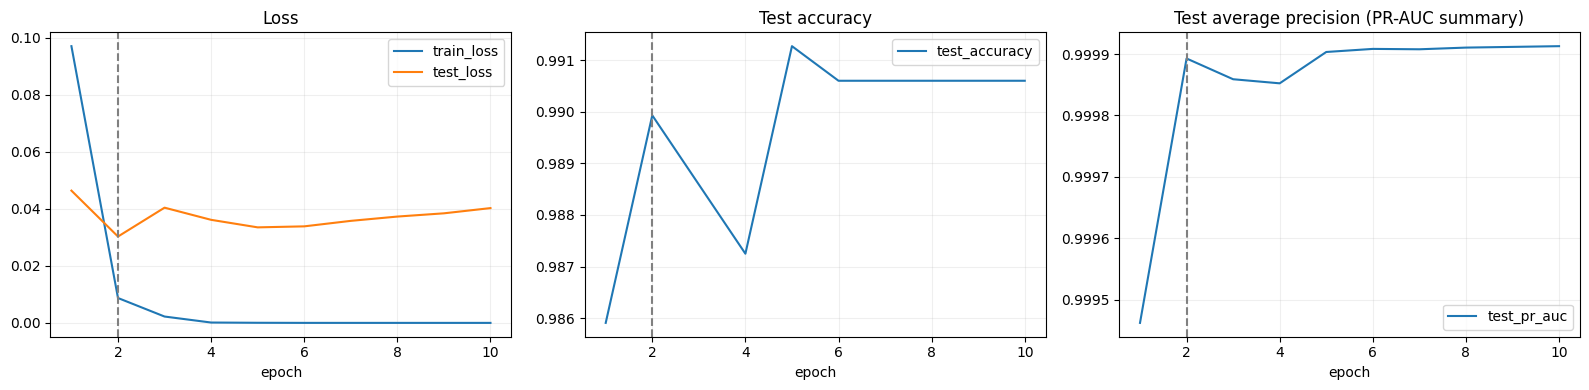

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
history_df.plot(x='epoch', y=['train_loss', 'test_loss'], ax=axes[0], title='Loss')
history_df.plot(x='epoch', y='test_accuracy', ax=axes[1], title='Test accuracy')
history_df.plot(x='epoch', y='test_pr_auc', ax=axes[2], title='Test average precision (PR-AUC summary)')
for ax in axes:
    ax.axvline(best_epoch, color='gray', linestyle='--', label='Best validation loss')
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()


---
# Evaluation
### Load the best checkpointed model.
`best.pt` is selected by validation loss automatically. Use a saved run path if evaluating in a later session. Only load checkpoints from a trusted run.


In [12]:
loaded_checkpoint_path = checkpoint_dir / 'best.pt'
loaded_checkpoint = torch.load(loaded_checkpoint_path, map_location='cpu', weights_only=True)
if loaded_checkpoint['dataset_version'] != dataset_version:
    raise ValueError('Checkpoint belongs to a different dataset archive')
if loaded_checkpoint['model_library']['version'] != version('maltorch'):
    raise ValueError('Use the MalTorch version saved in the checkpoint')
model = MalConv(**loaded_checkpoint['model_config']).to(device)
model.load_state_dict(loaded_checkpoint['model'])
model.eval()
# Restore exact eval membership and preprocessing from the saved run.
by_hash = data_dropped.set_index('hash', drop=False)
loaded_eval = by_hash.loc[loaded_checkpoint['split_hashes']['eval']].reset_index(drop=True)
preprocessing = loaded_checkpoint['preprocessing']
eval_dataset = ExecutableBytesDataset(DATA_PATH, loaded_eval, preprocessing['max_length'], preprocessing['padding_token'])
eval_loader = DataLoader(eval_dataset, batch_size=batch_size, shuffle=False, num_workers=0)
print(f'Loaded epoch {loaded_checkpoint["epoch"]}: {loaded_checkpoint_path}')
print(f'Saved validation metrics: {loaded_checkpoint["metrics"]}')


Loaded epoch 2: /Users/ronaldyu/Desktop/CU_Denver/AI_Cyber/Project/SCHOOL-AI_Cyber_Project/Training/Malware_Detection_xai/.models/20261106_142553_131610/best.pt
Saved validation metrics: {'epoch': 2, 'train_loss': 0.00872684726775384, 'test_loss': 0.030296040472395137, 'test_accuracy': 0.9899328859060402, 'test_pr_auc': 0.9998927335600556}


### Evaluate the held-out Eval split.
The decision threshold is fixed at 0.5. If choosing another threshold, use the validation split before running this cell.


,Eval
log_loss,0.0133
accuracy,0.9946
precision,0.9978
recall,0.9963
f1,0.9970
roc_auc,0.9997
average_precision,1.0000


              precision    recall  f1-score   support

      Benign       0.97      0.98      0.97       145
     Malware       1.00      1.00      1.00      1345

    accuracy                           0.99      1490
   macro avg       0.98      0.99      0.98      1490
weighted avg       0.99      0.99      0.99      1490



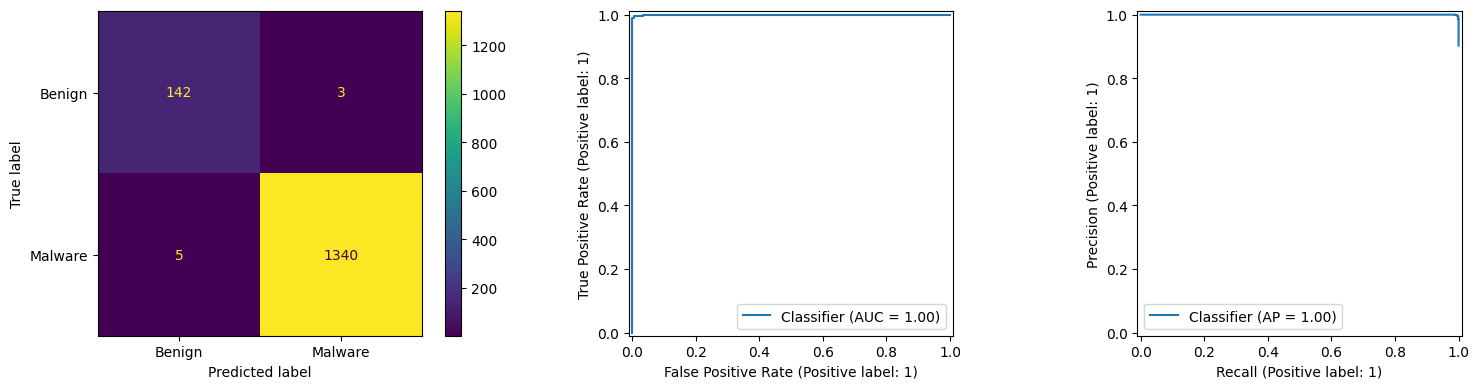

In [13]:
eval_labels, eval_probabilities = predict_probabilities(model, eval_loader)
eval_predictions = (eval_probabilities >= loaded_checkpoint['model_config']['threshold']).astype(int)
eval_metrics = pd.Series({
    'log_loss': metrics.log_loss(eval_labels, eval_probabilities, labels=[0, 1]),
    'accuracy': metrics.accuracy_score(eval_labels, eval_predictions),
    'precision': metrics.precision_score(eval_labels, eval_predictions, zero_division=0),
    'recall': metrics.recall_score(eval_labels, eval_predictions, zero_division=0),
    'f1': metrics.f1_score(eval_labels, eval_predictions, zero_division=0),
    'roc_auc': metrics.roc_auc_score(eval_labels, eval_probabilities),
    'average_precision': metrics.average_precision_score(eval_labels, eval_probabilities),
})
display(eval_metrics.to_frame('Eval').style.format('{:.4f}'))
print(metrics.classification_report(eval_labels, eval_predictions, labels=[0, 1],
                                    target_names=['Benign', 'Malware'], zero_division=0))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
metrics.ConfusionMatrixDisplay.from_predictions(eval_labels, eval_predictions, display_labels=['Benign', 'Malware'], ax=axes[0])
metrics.RocCurveDisplay.from_predictions(eval_labels, eval_probabilities, ax=axes[1])
metrics.PrecisionRecallDisplay.from_predictions(eval_labels, eval_probabilities, ax=axes[2])
fig.tight_layout()
plt.show()
pd.DataFrame({'hash': loaded_eval['hash'], 'label': eval_labels, 'malware_probability': eval_probabilities,
              'prediction': eval_predictions}).to_csv(checkpoint_dir / 'eval_predictions.csv', index=False)
eval_metrics.to_json(checkpoint_dir / 'eval_metrics.json', indent=2)


### Close dataset handles.
Run after evaluation (or before rerunning preprocessing cells). No sample files have been extracted.


In [14]:
for dataset in byte_datasets.values():
    dataset.close()
eval_dataset.close()


---
# Byte Attribution (Captum)
Explains which bytes of an executable push MalConv toward **malware** or **benign**. Run everything through the Evaluation cell that loads the best checkpoint; the full Evaluation run is not required. Files come from the **test** split so Eval stays held out. This section needs `captum` (`pip install captum`; add it to `requirements.in`). No sample is executed; the files are only read as bytes.

How it works:
- The explained quantity is the model's output **logit**. Positive means malware, and `sigmoid(logit)` is the malware probability.
- **Layer Integrated Gradients** attributes the logit to every byte position through the embedding layer, moving from an all-padding baseline (an empty file) to the real file. Scores are in logit units and sum to the logit minus the baseline logit.
- MalConv reads the file in non-overlapping windows of `stride` bytes, so attributions are also summed per window and per PE region (headers, each section, overlay) taken from the section table.

Attributions describe what this model reacts to, not what the file does. Files longer than `max_length` are explained on their first `max_length` bytes only.

### Set up the attribution helpers.

In [15]:
from captum.attr import LayerIntegratedGradients


# Explanation settings. Each file costs N_STEPS forward and backward passes over up to 1 MiB,
# so keep these small on CPU. Lower INTERNAL_BATCH_SIZE if memory is tight.
N_PER_CLASS = 2           # Benign and malware files explained.
N_STEPS = 24              # Integrated Gradients interpolation steps.
INTERNAL_BATCH_SIZE = 2   # Interpolation steps processed at once.
CLASS_NAMES = {0: 'benign', 1: 'malware'}
WINDOW = model_config['stride']
padding_token = model_config['padding_idx']


# Use the checkpoint model from the Evaluation section. Attribute through its embedding layer,
# because the byte IDs themselves are integers and have no gradient.
model.eval()
embedding_layer = next(module for module in model.modules() if isinstance(module, nn.Embedding))
if embedding_layer.num_embeddings != padding_token + 1:
    raise ValueError('Unexpected embedding layer; expected 256 byte values plus one padding token.')


# One logit per file, matching the training and evaluation cells.
def malconv_logit(tokens):
    return model(tokens).reshape(-1)


layer_ig = LayerIntegratedGradients(malconv_logit, embedding_layer)


# Attribute one file's logit to each byte position. The baseline is an all-padding input.
def explain_file(tokens):
    tokens = tokens.unsqueeze(0).to(device)
    baseline = torch.full_like(tokens, padding_token)
    attributions, delta = layer_ig.attribute(
        tokens,
        baselines=baseline,
        n_steps=N_STEPS,
        internal_batch_size=INTERNAL_BATCH_SIZE,
        return_convergence_delta=True,
    )
    with torch.no_grad():
        logit = malconv_logit(tokens).item()
        baseline_logit = malconv_logit(baseline).item()
    return {
        'byte_attr': attributions.sum(dim=-1)[0].detach().cpu().numpy(),  # Sum over embedding dimensions.
        'logit': logit,
        'baseline_logit': baseline_logit,
        'delta': delta.abs().item(),
    }


# Name the file regions of a PE (headers, each section, overlay) from its section table.
# Only header bytes are read; the file is never loaded or executed.
def pe_regions(raw_bytes, length):
    names = ['padding']
    region_ids = np.zeros(length, dtype=np.int16)
    spans = []

    def paint(name, start, end, record=True):
        start, end = max(0, start), min(end, len(raw_bytes))
        if end <= start:
            return
        names.append(name)
        region_ids[start:end] = len(names) - 1
        if record:
            spans.append((name, start, end))

    paint('other', 0, len(raw_bytes), record=False)
    pe_offset = int.from_bytes(raw_bytes[60:64], 'little')
    n_sections = int.from_bytes(raw_bytes[pe_offset + 6:pe_offset + 8], 'little')
    optional_size = int.from_bytes(raw_bytes[pe_offset + 20:pe_offset + 22], 'little')
    table = pe_offset + 24 + optional_size

    sections = []
    for index in range(min(n_sections, 96)):
        entry = raw_bytes[table + 40 * index:table + 40 * (index + 1)]
        if len(entry) < 40:
            break
        name = ''.join(chr(b) if 32 <= b < 127 else '?' for b in entry[:8].rstrip(b'\x00')) or 'unnamed'
        raw_size = int.from_bytes(entry[16:20], 'little')
        raw_pointer = int.from_bytes(entry[20:24], 'little')
        if raw_size:
            sections.append((name, raw_pointer, raw_pointer + raw_size))

    paint('headers', 0, min((s[1] for s in sections), default=table + 40 * n_sections))
    for name, start, end in sections:
        paint(name, start, end)
    if sections:
        paint('overlay', max(s[2] for s in sections), len(raw_bytes))
    return names, region_ids, spans


# Sum byte attributions inside each MalConv window.
def window_attributions(byte_attr):
    n_windows = len(byte_attr) // WINDOW
    return byte_attr[:n_windows * WINDOW].reshape(n_windows, WINDOW).sum(axis=1)


# Summary.
print(f'Embedding layer: {embedding_layer} | Window: {WINDOW} bytes | Baseline: padding token {padding_token}')

Embedding layer: Embedding(257, 8, padding_idx=256) | Window: 512 bytes | Baseline: padding token 256


### Run Integrated Gradients.
This is the slow step. A convergence delta that is large compared with the logit means `N_STEPS` is too low.

In [16]:
# Sample the same number of benign and malware files from the test split.
test_frame = byte_datasets['test'].frame
explain_positions = test_frame.groupby('label').sample(n=N_PER_CLASS, random_state=42).index.tolist()


results = []
for number, position in enumerate(explain_positions, start=1):
    tokens, _ = byte_datasets['test'][position]
    row = test_frame.loc[position]
    result = explain_file(tokens)

    # Recover the explained bytes from the token IDs to read the PE section table.
    n_bytes = int((tokens < padding_token).sum())
    raw_bytes = tokens[:n_bytes].to(torch.uint8).numpy().tobytes()
    region_names, region_ids, spans = pe_regions(raw_bytes, len(tokens))
    result.update({
        'hash': row['hash'], 'label': int(row['label']), 'size_bytes': int(row['size_bytes']),
        'n_bytes': n_bytes, 'region_names': region_names, 'region_ids': region_ids, 'spans': spans,
    })
    results.append(result)
    print(f'Explained file {number}/{len(explain_positions)}')

# Release the ZIP handle used for the test split.
byte_datasets['test'].close()


# Summary. The attribution sum should be close to logit minus baseline logit.
display(pd.DataFrame([{
    'hash': result['hash'][:12],
    'label': CLASS_NAMES[result['label']],
    'size': human_bytes(result['size_bytes']),
    'truncated': result['size_bytes'] > max_length,
    'malware_probability': 1 / (1 + np.exp(-result['logit'])),
    'logit': result['logit'],
    'baseline_logit': result['baseline_logit'],
    'attribution_sum': result['byte_attr'].sum(),
    'convergence_delta': result['delta'],
} for result in results]).style.format({
    'malware_probability': '{:.4f}', 'logit': '{:.3f}', 'baseline_logit': '{:.3f}',
    'attribution_sum': '{:.3f}', 'convergence_delta': '{:.3f}',
}).set_caption('Explained test files'))

Explained file 1/4
Explained file 2/4
Explained file 3/4
Explained file 4/4


,hash,label,size,truncated,malware_probability,logit,baseline_logit,attribution_sum,convergence_delta
0,e5c6eb60211e,benign,78.59 KiB,False,0.0000,-19.583,-0.014,-19.569,0.001
1,6df774a7ed52,benign,22.00 KiB,False,0.0000,-15.527,-0.014,-15.521,0.008
2,5509b588d61f,malware,119.97 KiB,False,0.9999,9.159,-0.014,9.183,0.011
3,3b9a31b84788,malware,112.50 KiB,False,0.9968,5.735,-0.014,5.754,0.006


### Plot the attribution along each file.
**Red** pushes toward malware and **blue** toward benign. Each bar is one MalConv window. Gray bands are PE sections.

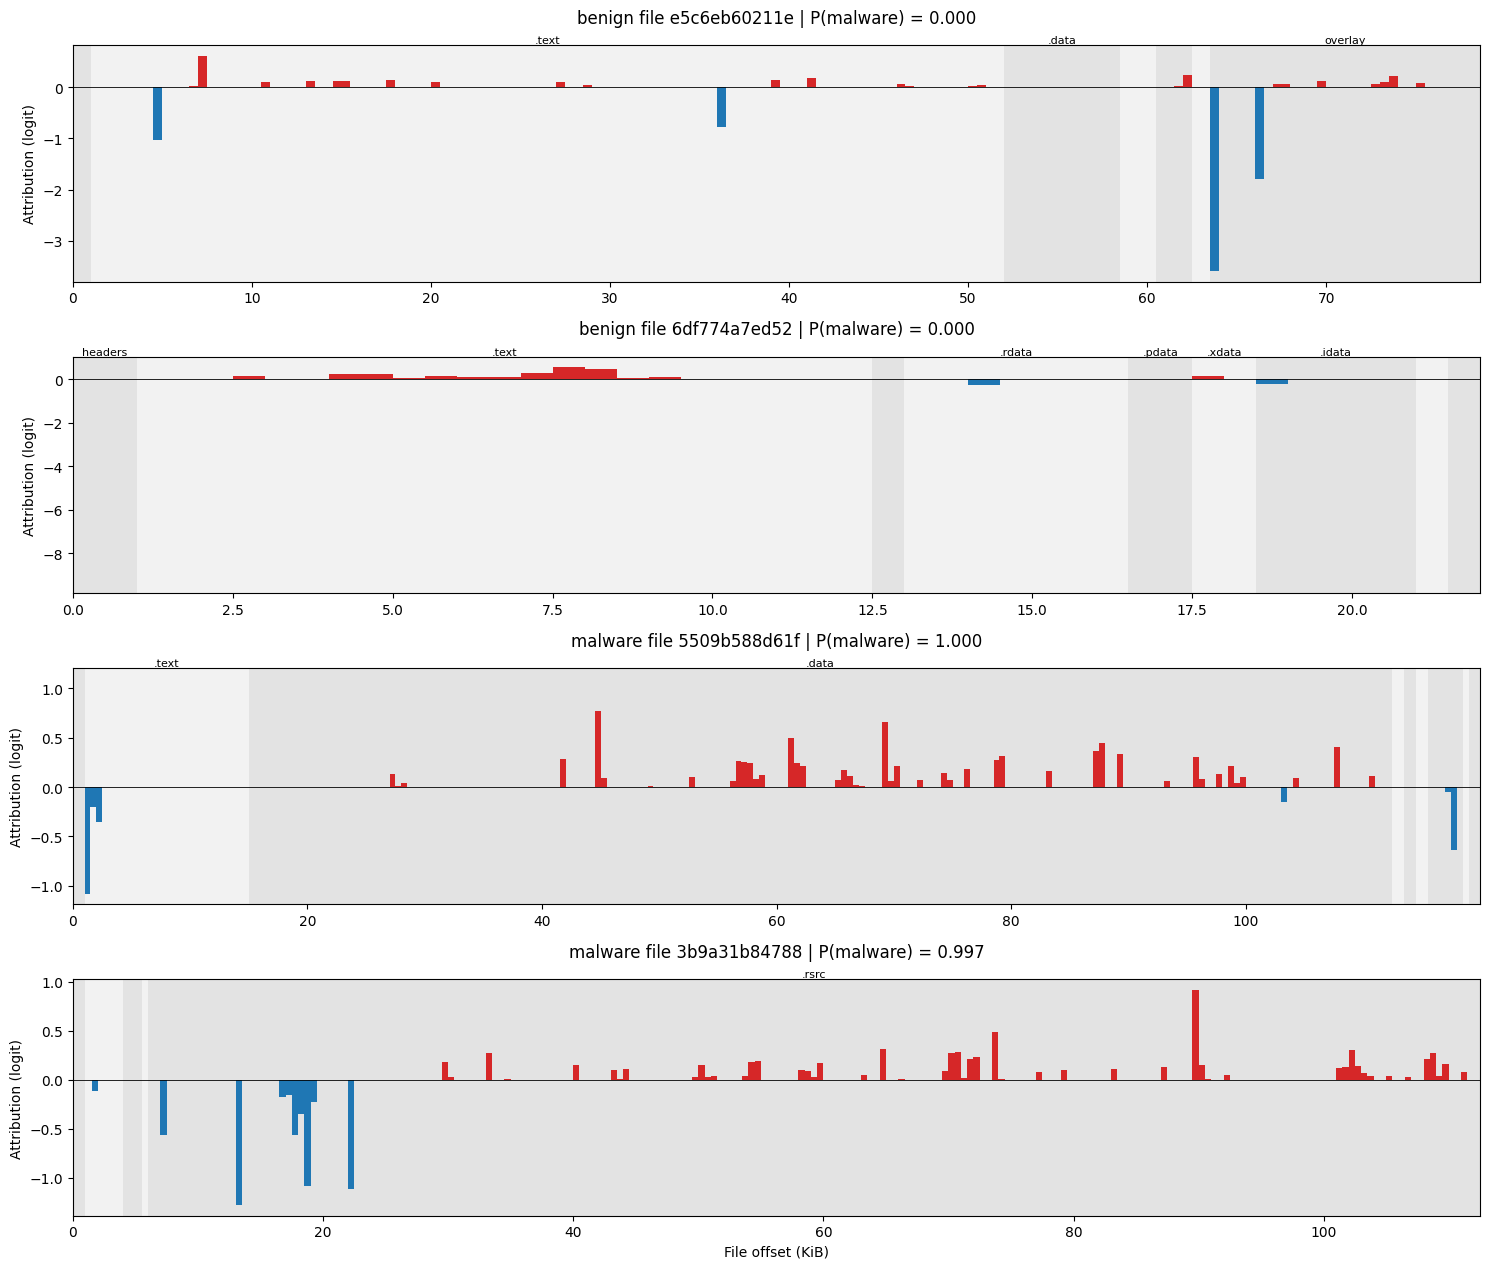

In [17]:
fig, axes = plt.subplots(len(results), 1, figsize=(15, 3.2 * len(results)), squeeze=False)
for ax, result in zip(axes[:, 0], results):
    window_attr = window_attributions(result['byte_attr'])
    offsets = np.arange(len(window_attr)) * WINDOW / 1024
    x_limit = max(result['n_bytes'], WINDOW) / 1024

    # Shade the PE sections and label the wide ones.
    for number, (name, start, end) in enumerate(result['spans']):
        ax.axvspan(start / 1024, end / 1024, color='gray', alpha=0.10 if number % 2 else 0.22, linewidth=0)
        if (end - start) / 1024 > 0.04 * x_limit:
            ax.text((start + end) / 2048, 1.0, name, transform=ax.get_xaxis_transform(),
                    ha='center', va='bottom', fontsize=8)

    ax.fill_between(offsets, window_attr, 0, where=window_attr > 0, color='tab:red', step='post', linewidth=0)
    ax.fill_between(offsets, window_attr, 0, where=window_attr < 0, color='tab:blue', step='post', linewidth=0)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_xlim(0, x_limit)
    ax.set_ylabel('Attribution (logit)')
    ax.set_title(
        f"{CLASS_NAMES[result['label']]} file {result['hash'][:12]} | "
        f"P(malware) = {1 / (1 + np.exp(-result['logit'])):.3f}",
        pad=16,
    )
axes[-1, 0].set_xlabel('File offset (KiB)')
fig.tight_layout()
plt.show()

### Attribution by PE region.
Compare each region's share of the total absolute attribution with its share of the bytes. A region with a much larger attribution share is disproportionately influential.

,bytes,net_attribution,byte_share,abs_attribution_share
region,,,,
overlay,"15,448",-16.120,19.2%,49.0%
.text,"52,224",-2.367,64.9%,43.3%
.rsrc,"2,048",-0.249,2.5%,2.8%
.pdata,"2,048",-1.015,2.5%,2.7%
.reloc,"1,024",0.111,1.3%,1.5%
.data,"6,656",0.045,8.3%,0.3%
headers,"1,024",0.026,1.3%,0.3%


,bytes,net_attribution,byte_share,abs_attribution_share
region,,,,
.text,"11,776",-11.651,52.3%,69.9%
.rdata,"3,584",-2.764,15.9%,20.0%
.idata,"2,560",-1.026,11.4%,7.0%
.xdata,"1,024",0.176,4.5%,1.7%
.pdata,"1,024",-0.254,4.5%,1.4%
.CRT,512,-0.002,2.3%,0.0%
headers,"1,024",0.000,4.5%,0.0%
.data,512,0.000,2.3%,0.0%
.tls,512,0.000,2.3%,0.0%


,bytes,net_attribution,byte_share,abs_attribution_share
region,,,,
.data,"99,840",12.346,81.3%,76.9%
.text,"14,336",-3.565,11.7%,12.5%
overlay,992,1.096,0.8%,8.6%
.rsrc,"3,072",-0.694,2.5%,2.0%
headers,"1,024",0.000,0.8%,0.0%
.data4,"1,024",0.000,0.8%,0.0%
.data3,"1,024",0.000,0.8%,0.0%
.data2,"1,024",0.000,0.8%,0.0%
.reloc,512,0.000,0.4%,0.0%


,bytes,net_attribution,byte_share,abs_attribution_share
region,,,,
.rsrc,"109,056",6.049,94.7%,96.1%
.text,"3,072",-0.062,2.7%,3.3%
.data,512,-0.221,0.4%,0.6%
headers,"1,024",-0.012,0.9%,0.1%
.rdata,"1,536",0.000,1.3%,0.0%


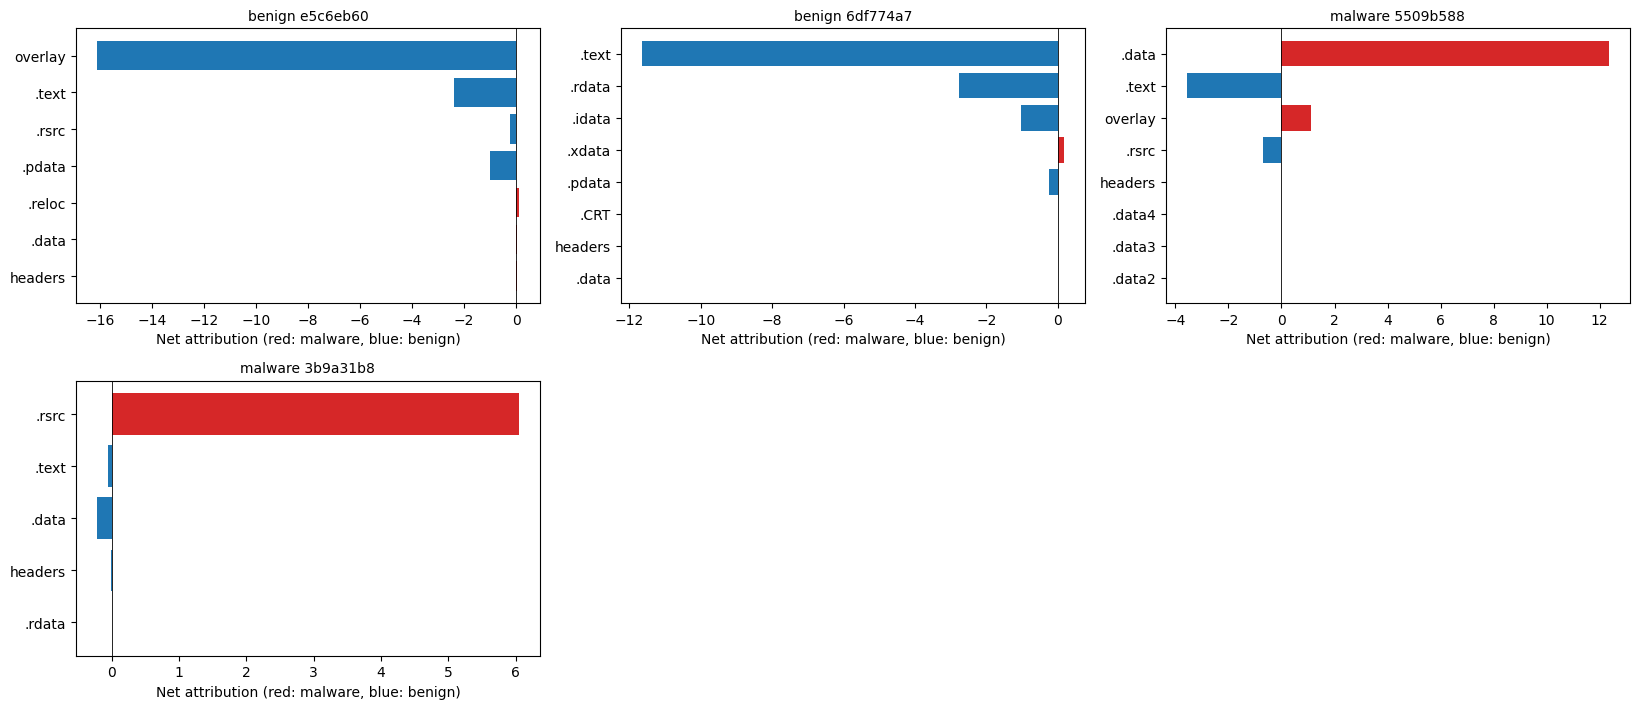

In [18]:
# Sum the byte attributions inside each named region of each file.
def region_summary(result):
    names, region_ids, byte_attr = result['region_names'], result['region_ids'], result['byte_attr']
    frame = pd.DataFrame({
        'region': names,
        'bytes': np.bincount(region_ids, minlength=len(names)),
        'net_attribution': np.bincount(region_ids, weights=byte_attr, minlength=len(names)),
        'abs_attribution': np.bincount(region_ids, weights=np.abs(byte_attr), minlength=len(names)),
    })
    frame = frame[(frame['region'] != 'padding') & (frame['bytes'] > 0)].groupby('region', sort=False).sum()
    frame['byte_share'] = frame['bytes'] / frame['bytes'].sum()
    frame['abs_attribution_share'] = frame['abs_attribution'] / max(frame['abs_attribution'].sum(), 1e-12)
    return frame.sort_values('abs_attribution_share', ascending=False)


region_tables = [region_summary(result) for result in results]
for result, table in zip(results, region_tables):
    display(table.drop(columns='abs_attribution').style.format({
        'bytes': '{:,.0f}', 'net_attribution': '{:.3f}', 'byte_share': '{:.1%}', 'abs_attribution_share': '{:.1%}',
    }).set_caption(f"{CLASS_NAMES[result['label']]} file {result['hash'][:12]}"))


# Net attribution per region for every explained file.
n_columns = min(3, len(results))
n_rows = -(-len(results) // n_columns)
fig, axes = plt.subplots(n_rows, n_columns, figsize=(5.5 * n_columns, 3.6 * n_rows), squeeze=False)
for ax, result, table in zip(axes.ravel(), results, region_tables):
    net = table['net_attribution'].head(8)
    ax.barh(net.index, net.values, color=np.where(net.values > 0, 'tab:red', 'tab:blue'))
    ax.invert_yaxis()
    ax.axvline(0, color='black', linewidth=0.6)
    ax.set_title(f"{CLASS_NAMES[result['label']]} {result['hash'][:8]}", fontsize=10)
    ax.set_xlabel('Net attribution (red: malware, blue: benign)')
for ax in axes.ravel()[len(results):]:
    ax.axis('off')
fig.tight_layout()
plt.show()

### Most influential windows.
The five windows with the largest absolute attribution in each file.

In [19]:
top_rows = []
for result in results:
    window_attr = window_attributions(result['byte_attr'])
    total = max(np.abs(window_attr).sum(), 1e-12)
    for window_index in np.argsort(np.abs(window_attr))[::-1][:5]:
        start = int(window_index) * WINDOW
        top_rows.append({
            'file': f"{CLASS_NAMES[result['label']]} {result['hash'][:8]}",
            'offset': f'0x{start:08x}',
            'region': result['region_names'][result['region_ids'][start]],
            'attribution': window_attr[window_index],
            'share_of_total': abs(window_attr[window_index]) / total,
        })


# Summary.
display(pd.DataFrame(top_rows).style.format({'attribution': '{:+.3f}', 'share_of_total': '{:.1%}'})
        .set_caption(f'Top windows ({WINDOW} bytes each)'))

,file,offset,region,attribution,share_of_total
0,benign e5c6eb60,0x00010400,overlay,-3.589,12.7%
1,benign e5c6eb60,0x0000fe00,overlay,-3.584,12.7%
2,benign e5c6eb60,0x00010000,overlay,-2.758,9.8%
3,benign e5c6eb60,0x00011200,overlay,-2.045,7.2%
4,benign e5c6eb60,0x00010800,overlay,-1.791,6.3%
5,benign 6df774a7,0x00000400,.text,-9.323,41.6%
6,benign 6df774a7,0x00002c00,.text,-5.189,23.1%
7,benign 6df774a7,0x00003400,.rdata,-2.445,10.9%
8,benign 6df774a7,0x00004c00,.idata,-0.822,3.7%
9,benign 6df774a7,0x00001e00,.text,+0.544,2.4%
